## **Import Library**

Pada tahap awal, dilakukan pemanggilan beberapa library Python yang dibutuhkan untuk proses pengolahan dan visualisasi data. Pandas digunakan untuk membaca serta mengelola dataset, NumPy membantu pengolahan data numerik, sedangkan Matplotlib digunakan untuk membuat grafik. Library display digunakan untuk menampilkan tabel agar hasil pengolahan data lebih mudah diperiksa.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

## **Membaca Data**

Dataset yang digunakan adalah Students Performance, yang berisi informasi karakteristik siswa dan nilai ujian matematika, membaca, serta menulis. Dataset hasil cleansing dibaca menggunakan Pandas untuk memastikan data dapat digunakan dalam proses visualisasi. Pemeriksaan awal juga dilakukan untuk mengetahui jumlah baris, kolom, dan contoh data yang tersedia.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
file_path = '/content/drive/MyDrive/Colab Notebooks/DatMin/StudentsPerformance.csv'

df = pd.read_csv(file_path)

print("Dataset berhasil dibaca")
print("Jumlah baris dan kolom:", df.shape)
display(df.head())

print("\n=== KONDISI DATA SEBELUM CLEANSING ===")
print("Ukuran dataset:", df.shape)
print("\nJumlah nilai kosong setiap kolom:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

Dataset berhasil dibaca
Jumlah baris dan kolom: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



=== KONDISI DATA SEBELUM CLEANSING ===
Ukuran dataset: (1000, 8)

Jumlah nilai kosong setiap kolom:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Jumlah baris duplikat: 0


## **Membersihkan Data**

Pembersihan data dilakukan untuk meningkatkan konsistensi dataset sebelum dianalisis. Proses ini mencakup pembuatan salinan dataset, penghapusan spasi yang tidak diperlukan pada teks, penanganan nilai kosong, pemeriksaan data duplikat, serta pemeriksaan validitas nilai ujian. Nilai ujian dipastikan berbentuk numerik dan berada dalam rentang 0–100. Tahap ini membantu mempersiapkan data agar dapat digunakan dalam perhitungan statistik dan pembuatan visualisasi.

In [ ]:
# 2. MEMBUAT SALINAN DATASET
data = df.copy()

# ==========================================
# 3. MEMBERSIHKAN SPASI KOLOM DAN TEKS
data.columns = data.columns.str.strip()

text_cols = data.select_dtypes(include='object').columns

for col in text_cols:
    data[col] = data[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# ==========================================
# 4. MENANGANI NILAI KOSONG
# Kolom kategorikal diisi dengan modus jika ada nilai kosong
categorical_cols = [
    'gender',
    'race/ethnicity',
    'parental level of education',
    'lunch',
    'test preparation course'
]

for col in categorical_cols:
    if col in data.columns and data[col].isnull().any():
        data[col] = data[col].fillna(data[col].mode()[0])

# Kolom nilai ujian dikonversi menjadi numerik
score_cols = ['math score', 'reading score', 'writing score']

for col in score_cols:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors='coerce')

# ==========================================
# 5. MENANGANI NILAI KOSONG PADA NILAI UJIAN
# Nilai kosong diisi menggunakan median kolom
for col in score_cols:
    if col in data.columns and data[col].isnull().any():
        data[col] = data[col].fillna(data[col].median())

# ==========================================
# 6. MENGHAPUS DATA DUPLIKAT
jumlah_duplikat = data.duplicated().sum()
data = data.drop_duplicates()

# ==========================================
# 7. MEMERIKSA RENTANG NILAI UJIAN
# Nilai ujian yang tidak valid (di luar 0-100)
# diubah menjadi NaN, lalu diisi dengan median
for col in score_cols:
    if col in data.columns:
        data.loc[~data[col].between(0, 100), col] = np.nan

        if data[col].isnull().any():
            data[col] = data[col].fillna(data[col].median())

# ==========================================
# 8. HASIL SETELAH CLEANSING
print("\n=== HASIL SETELAH CLEANSING ===")
print("Ukuran dataset:", data.shape)
print("Jumlah baris duplikat yang dihapus:", jumlah_duplikat)

print("\nJumlah nilai kosong setelah cleansing:")
print(data.isnull().sum())

print("\nStatistik deskriptif nilai ujian:")
display(data[score_cols].describe())

print("\nPreview dataset setelah cleansing:")
display(data.head())

# ==========================================
# 9. MENYIMPAN DATA HASIL CLEANSING
# ==========================================
output_path = '/content/drive/MyDrive/Colab Notebooks/DatMin/StudentsPerformance_Cleaned.csv'
data.to_csv(output_path, index=False)

print("\nCleansing berhasil diselesaikan!")
print("File hasil disimpan di:", output_path)



=== HASIL SETELAH CLEANSING ===
Ukuran dataset: (1000, 8)
Jumlah baris duplikat yang dihapus: 0

Jumlah nilai kosong setelah cleansing:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Statistik deskriptif nilai ujian:


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000



Preview dataset setelah cleansing:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72.0,72.0,74.0
1,female,group C,some college,standard,completed,69.0,90.0,88.0
2,female,group B,master's degree,standard,none,90.0,95.0,93.0
3,male,group A,associate's degree,free/reduced,none,47.0,57.0,44.0
4,male,group C,some college,standard,none,76.0,78.0,75.0



Cleansing berhasil diselesaikan!
File hasil disimpan di: /content/drive/MyDrive/Colab Notebooks/DatMin/StudentsPerformance_Cleaned.csv


# **DATA VISUALIZATION**

# **Visualisasi--Bar Chart**

Bar chart digunakan untuk membandingkan rata-rata nilai matematika, membaca, dan menulis berdasarkan gender siswa. Setiap kelompok gender ditampilkan dalam bentuk batang dengan warna berbeda untuk mewakili jenis ujian. Sumbu horizontal menunjukkan gender, sedangkan sumbu vertikal menunjukkan rata-rata nilai. Visualisasi ini memudahkan pengamatan terhadap perbedaan rata-rata hasil ujian antara siswa laki-laki dan perempuan.

<Figure size 900x600 with 0 Axes>

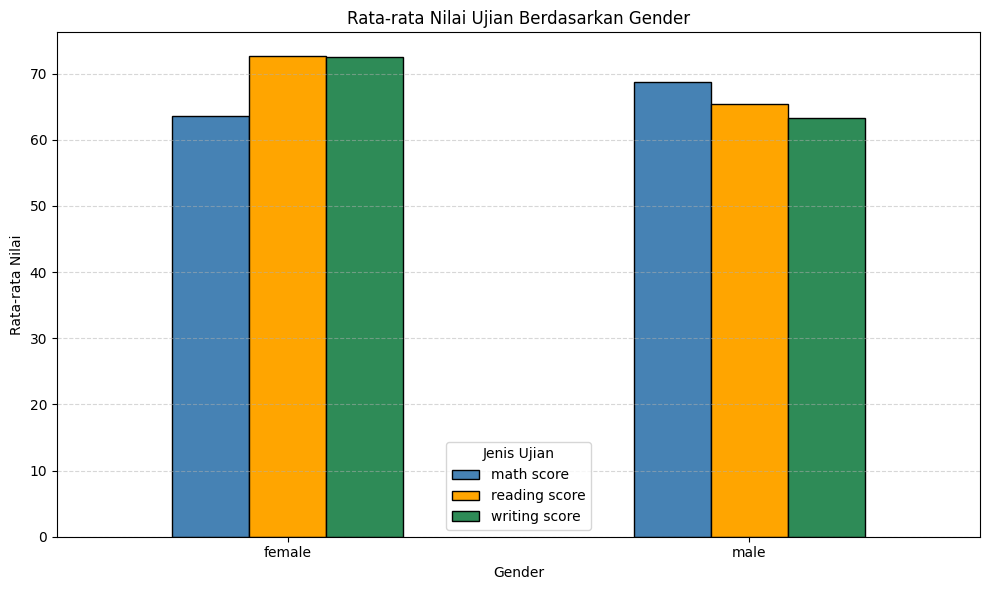

In [ ]:
avg_gender = data.groupby('gender')[score_cols].mean()

plt.figure(figsize=(9, 6))

avg_gender.plot(
    kind='bar',
    figsize=(10, 6),
    color=['steelblue', 'orange', 'seagreen'],
    edgecolor='black'
)

plt.title('Rata-rata Nilai Ujian Berdasarkan Gender')
plt.xlabel('Gender')
plt.ylabel('Rata-rata Nilai')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Jenis Ujian')
plt.tight_layout()
plt.show()

# **Visualisasi--Line Chart**

Line chart digunakan untuk memperlihatkan perbedaan rata-rata nilai ujian berdasarkan tingkat pendidikan orang tua. Grafik menampilkan tiga garis yang mewakili nilai matematika, membaca, dan menulis pada setiap kategori pendidikan orang tua. Marker digunakan untuk menunjukkan titik data pada setiap kategori, sedangkan grid membantu pembacaan nilai pada sumbu vertikal. Meskipun berbentuk garis, grafik ini digunakan untuk membandingkan kategori pendidikan, bukan untuk menunjukkan perubahan dari waktu ke waktu.

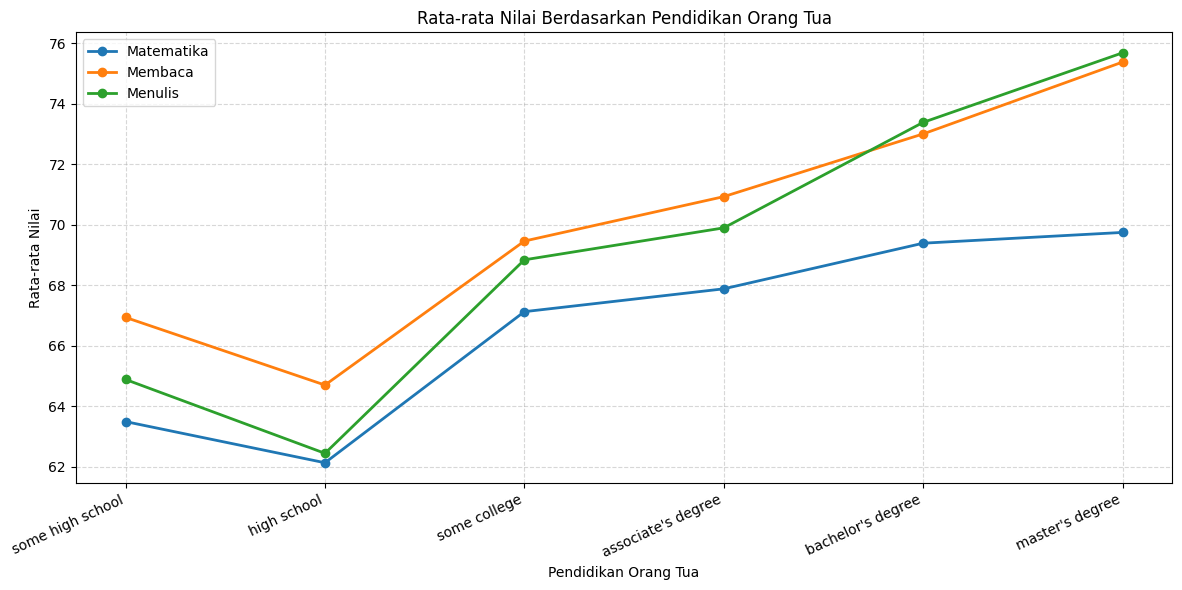

In [ ]:
education_order = [
    'some high school',
    'high school',
    'some college',
    "associate's degree",
    "bachelor's degree",
    "master's degree"
]

avg_education = (
    data.groupby('parental level of education')[score_cols]
    .mean()
    .reindex(education_order)
)

plt.figure(figsize=(12, 6))

for col, label in zip(
    score_cols,
    ['Matematika', 'Membaca', 'Menulis']
):
    plt.plot(
        avg_education.index,
        avg_education[col],
        marker='o',
        linewidth=2,
        linestyle='-',
        label=label
    )

plt.title('Rata-rata Nilai Berdasarkan Pendidikan Orang Tua')
plt.xlabel('Pendidikan Orang Tua')
plt.ylabel('Rata-rata Nilai')
plt.xticks(rotation=25, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# **Visualisasi--Histogram**

Histogram digunakan untuk menggambarkan distribusi nilai matematika siswa. Nilai dikelompokkan ke dalam beberapa interval, kemudian frekuensi siswa pada setiap interval ditampilkan melalui batang histogram. Garis vertikal putus-putus menunjukkan rata-rata nilai matematika. Melalui visualisasi ini, persebaran nilai, interval yang memiliki frekuensi tinggi, dan posisi rata-rata dapat diamati dengan lebih mudah.

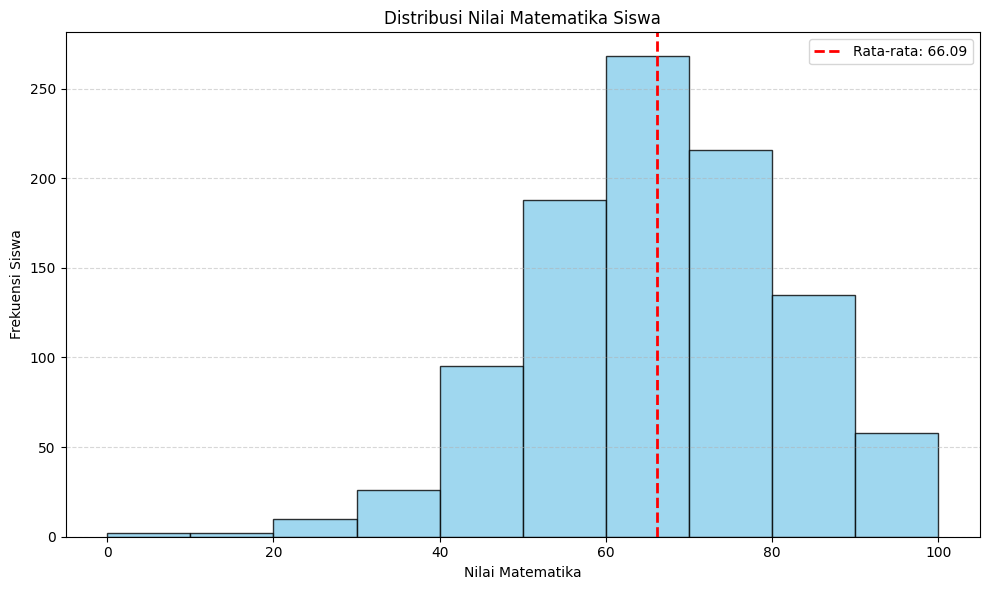

In [ ]:
math_scores = data['math score'].dropna()

plt.figure(figsize=(10, 6))

plt.hist(
    math_scores,
    bins=10,
    color='skyblue',
    edgecolor='black',
    alpha=0.8
)

plt.axvline(
    math_scores.mean(),
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Rata-rata: {math_scores.mean():.2f}'
)

plt.title('Distribusi Nilai Matematika Siswa')
plt.xlabel('Nilai Matematika')
plt.ylabel('Frekuensi Siswa')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# **Visualisasi--Scatter plot**

Scatter plot digunakan untuk mengamati hubungan antara nilai matematika dan nilai membaca. Setiap titik pada grafik mewakili satu siswa, dengan nilai matematika pada sumbu horizontal dan nilai membaca pada sumbu vertikal. Pola persebaran titik membantu memperlihatkan arah hubungan antara kedua variabel. Nilai korelasi Pearson ditambahkan sebagai informasi untuk menunjukkan arah dan kekuatan hubungan linear. Korelasi yang positif menunjukkan kecenderungan kedua nilai meningkat bersama, tetapi tidak membuktikan hubungan sebab-akibat.

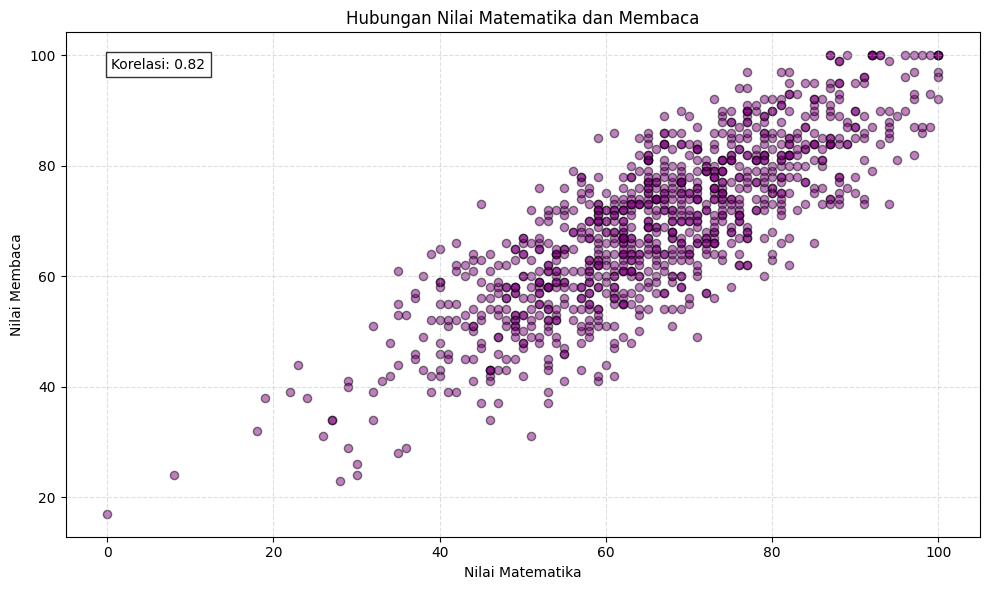

Nilai korelasi: 0.818


In [ ]:
scatter_data = data[['math score', 'reading score']].dropna()

plt.figure(figsize=(10, 6))

plt.scatter(
    scatter_data['math score'],
    scatter_data['reading score'],
    color='purple',
    alpha=0.5,
    edgecolors='black',
    s=35
)

korelasi = scatter_data['math score'].corr(
    scatter_data['reading score']
)

plt.title('Hubungan Nilai Matematika dan Membaca')
plt.xlabel('Nilai Matematika')
plt.ylabel('Nilai Membaca')
plt.grid(True, linestyle='--', alpha=0.4)

plt.text(
    0.05, 0.95,
    f'Korelasi: {korelasi:.2f}',
    transform=plt.gca().transAxes,
    va='top',
    bbox=dict(facecolor='white', alpha=0.8)
)

plt.tight_layout()
plt.show()

print("Nilai korelasi:", round(korelasi, 3))

# **Visualisasi--Pie Chart**

Pie chart digunakan untuk menggambarkan proporsi siswa berdasarkan status kursus persiapan ujian. Setiap bagian lingkaran mewakili kategori keikutsertaan kursus, sedangkan persentase menunjukkan bagian masing-masing kategori terhadap keseluruhan data. Visualisasi ini membantu membandingkan proporsi siswa yang tidak mengikuti kursus dengan siswa yang telah menyelesaikan kursus persiapan ujian.

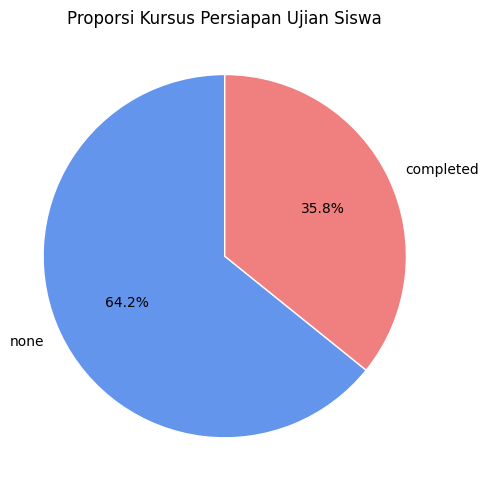

Jumlah siswa berdasarkan kursus persiapan:


,Jumlah Siswa
test preparation course,
none,642
completed,358


In [ ]:
preparation_counts = data['test preparation course'].value_counts()

plt.figure(figsize=(5, 5))

plt.pie(
    preparation_counts.values,
    labels=preparation_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['cornflowerblue', 'lightcoral'],
    wedgeprops={'edgecolor': 'white'}
)

plt.title('Proporsi Kursus Persiapan Ujian Siswa')
plt.axis('equal')
plt.tight_layout()
plt.show()

print("Jumlah siswa berdasarkan kursus persiapan:")
display(preparation_counts.to_frame(name='Jumlah Siswa'))


# **Ringkasan Statistik**

Ringkasan statistik digunakan untuk mengetahui karakteristik dasar nilai matematika, membaca, dan menulis. Informasi yang ditampilkan meliputi jumlah data valid, rata-rata, standar deviasi, nilai minimum, kuartil pertama, median, kuartil ketiga, dan nilai maksimum. Hasil ini melengkapi visualisasi dengan memberikan gambaran numerik mengenai pusat data dan penyebaran nilai ujian siswa.

In [ ]:
print("Statistik deskriptif nilai ujian:")
display(data[score_cols].describe().round(2))

Statistik deskriptif nilai ujian:


,math score,reading score,writing score
count,1000.00,1000.00,1000.00
mean,66.09,69.17,68.05
std,15.16,14.60,15.20
min,0.00,17.00,10.00
25%,57.00,59.00,57.75
50%,66.00,70.00,69.00
75%,77.00,79.00,79.00
max,100.00,100.00,100.00


# **Kesimpulan**

Berdasarkan hasil pembersihan data, pengolahan statistik, dan lima visualisasi yang telah dibuat, dataset Students Performance dapat digunakan untuk mengamati perbedaan rata-rata nilai berdasarkan gender dan pendidikan orang tua, distribusi nilai matematika, hubungan antara nilai matematika dan membaca, serta proporsi siswa berdasarkan keikutsertaan kursus persiapan ujian.

Setiap grafik memberikan sudut pandang yang berbeda terhadap data. Bar chart membantu membandingkan kelompok, line chart memperlihatkan perbedaan antarkategori, histogram menunjukkan distribusi nilai, scatter plot menggambarkan hubungan dua variabel numerik, dan pie chart menyajikan proporsi kategori. Secara keseluruhan, visualisasi membantu menyederhanakan data menjadi informasi yang lebih mudah dipahami.